In [1]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import ast
import seaborn as sns
from adjustText import adjust_text

#data loading
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df_ind = df[(df['job_country'] == 'India')].dropna(subset=['salary_year_avg'])

In [7]:
job_titles = df_ind['job_title_short'].value_counts().index[:6].tolist()

In [10]:
df_ind_top6 = df_ind[df_ind['job_title_short'].isin(job_titles)]

In [17]:
job_order=df_ind_top6.groupby('job_title_short')['salary_year_avg'].median().sort_values(ascending=False).index

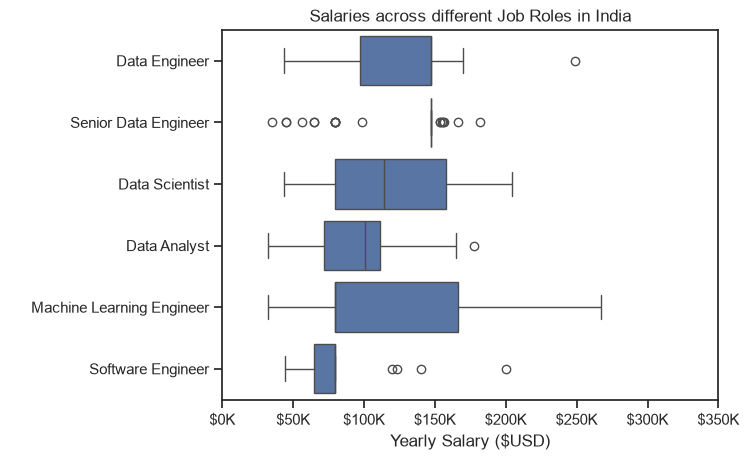

In [42]:
sns.boxplot(data=df_ind_top6, x='salary_year_avg', y='job_title_short', order=job_order)
sns.set_theme(style='ticks')

plt.title('Salaries across different Job Roles in India')
plt.xlabel('Yearly Salary ($USD)')
plt.ylabel(' ')
plt.xlim(0,350000)
ticks_x=plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K')
plt.gca().xaxis.set_major_formatter(ticks_x)
plt.show()

# Investigating Median Salary VS SKill for Data Analysts

In [19]:
df_DA_ind = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()

In [21]:
df_DA_ind = df_DA_ind.dropna(subset='salary_year_avg')
df_DA_ind = df_DA_ind.explode('job_skills')

In [23]:
df_DA_ind[['salary_year_avg','job_skills']].head(5)

,salary_year_avg,job_skills
11412,50400.0,python
11412,50400.0,sql
11412,50400.0,aws
11412,50400.0,azure
11412,50400.0,excel


In [28]:
df_DA_toppay = df_DA_ind.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='median',ascending=False)
df_DA_toppay = df_DA_toppay.head(10)

In [31]:
df_DA_topskills = df_DA_ind.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by='count',ascending=False)
df_DA_topskills = df_DA_topskills.head(10).sort_values(by='median')
df_DA_topskills

,count,median
job_skills,,
aws,12,79200.0
r,18,79200.0
oracle,11,79200.0
azure,15,93600.0
python,36,96050.0
sql,46,96050.0
excel,39,98500.0
tableau,20,108087.5
power bi,17,111175.0


C:\Users\prajw\AppData\Local\Temp\ipykernel_11016\30986390.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


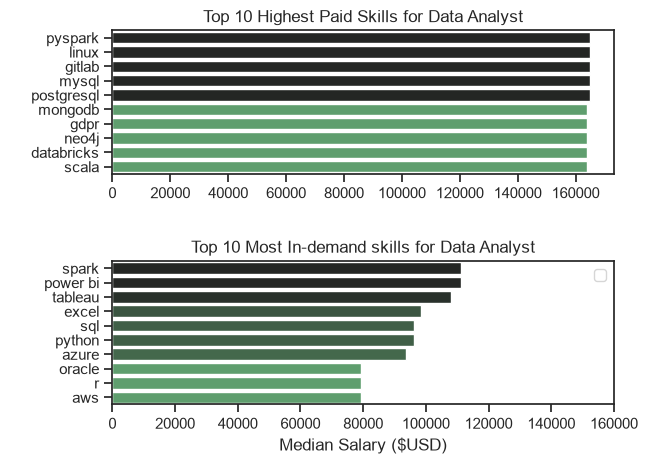

In [38]:
fig, ax= plt.subplots(2,1)

#sns.set_theme(style='ticks')

#df_DA_toppay.plot(kind='barh', y='median', ax=ax[0], legend=False)
sns.barplot(data=df_DA_toppay, x='median', y=df_DA_toppay.index, ax=ax[0], hue='median', palette='dark:g_r')
ax[0].legend().remove()
ax[0].set_title('Top 10 Highest Paid Skills for Data Analyst')
ax[0].set_xlabel(' ')
ax[0].set_ylabel(' ')

#df_DA_topskills.plot(kind='barh', y='median', ax=ax[1], legend=False)
sns.barplot(data=df_DA_topskills, x='median', y=df_DA_topskills.index, ax=ax[1], hue='median', palette='dark:g_r', legend=False)
ax[1].set_title('Top 10 Most In-demand skills for Data Analyst')
ax[1].set_xlabel('Median Salary ($USD)')
ax[1].set_ylabel(' ')
ax[1].invert_yaxis()
fig.tight_layout()
plt.legend()
plt.xlim(0,160000)
plt.show()